<a href="https://colab.research.google.com/github/Christy-Roy-tech/Plant_Disease_detection_system/blob/main/potato_disease_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Potato Leaf Disease Classifier — Early Blight / Late Blight / Healthy

Run the cells **in order, top to bottom**. Edit the two paths in **Cell: CONFIG** before running anything else.

Each stage below prints or plots something concrete ("proof") before you move to the next stage — class counts and sample images,
per-epoch accuracy printed live, training curves, a test-set confusion matrix, and sample predictions — so you can verify things
are working correctly before committing to the full epoch count or before trusting the final exported model.

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
Mounted at /content/drive


In [2]:
# Install extra packages (torch/torchvision/sklearn/matplotlib are preinstalled in Colab)
!pip install -q onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 83.4 MB/s eta 0:00:00


In [3]:
import os
import json
from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())

Torch: 2.11.0+cu130 | CUDA available: True


In [4]:
# ============================== CONFIG — EDIT THESE ==============================
# DATASET_DIR must contain a train/ and val/ subfolder, each with the SAME
# set of class subfolders inside, e.g.:
#   DATASET_DIR/train/Early_blight/*.jpg   DATASET_DIR/val/Early_blight/*.jpg
#   DATASET_DIR/train/Late_blight/*.jpg    DATASET_DIR/val/Late_blight/*.jpg
#   DATASET_DIR/train/healthy/*.jpg        DATASET_DIR/val/healthy/*.jpg
# (whatever your PlantVillage folder names actually are — the script reads
# the subfolder names directly, so it doesn't matter if they're capitalized
# differently or use underscores)
DATASET_DIR = "/content/drive/MyDrive/potato_dataset"
TRAIN_DIR = f"{DATASET_DIR}/train"
VAL_DIR   = f"{DATASET_DIR}/val"

# OUTPUT_DIR is where checkpoints, the best model, plots, and the ONNX export
# all get saved. It will be created if it doesn't exist.
OUTPUT_DIR  = "/content/drive/MyDrive/potato_model"
# ===================================================================================

os.makedirs(OUTPUT_DIR, exist_ok=True)

CHECKPOINT_PATH  = f"{OUTPUT_DIR}/checkpoint.pt"
BEST_MODEL_PATH  = f"{OUTPUT_DIR}/best_model.pt"
ONNX_EXPORT_PATH = f"{OUTPUT_DIR}/potato_disease_model.onnx"
LOG_PATH         = f"{OUTPUT_DIR}/train_log.csv"

IMG_SIZE      = 224
BATCH_SIZE    = 32
NUM_WORKERS   = 2
NUM_EPOCHS    = 25
LR            = 3e-4
WEIGHT_DECAY  = 1e-4

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cuda


### Proof #1 — confirm the dataset loaded correctly
Check the detected class names and counts in both `train/` and `val/` below, and look at the sample image from each class,
**before** continuing. If the class count isn't 3, the class names don't match between `train/` and `val/`, or a sample
image looks wrong, fix `DATASET_DIR` above and re-run this cell.

Classes found in train/: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Classes found in val/:   ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Train image counts: {'Potato___Early_blight': 813, 'Potato___Late_blight': 800, 'Potato___healthy': 121}
Val image counts:   {'Potato___Early_blight': 200, 'Potato___Late_blight': 200, 'Potato___healthy': 31}


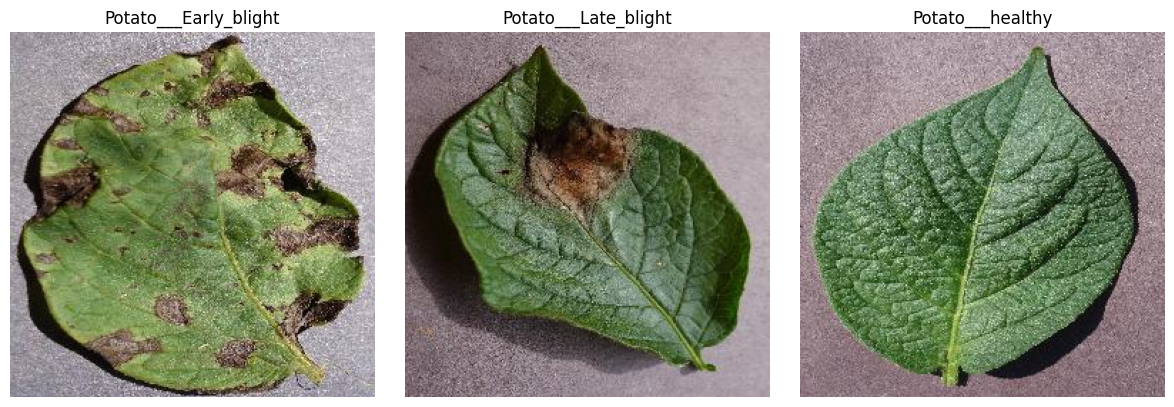

In [5]:
train_class_dirs = sorted([d for d in Path(TRAIN_DIR).iterdir() if d.is_dir()])
val_class_dirs   = sorted([d for d in Path(VAL_DIR).iterdir() if d.is_dir()])

CLASS_NAMES = [d.name for d in train_class_dirs]
val_class_names = [d.name for d in val_class_dirs]

print("Classes found in train/:", CLASS_NAMES)
print("Classes found in val/:  ", val_class_names)

if set(CLASS_NAMES) != set(val_class_names):
    print("WARNING: train/ and val/ class names don't match exactly — fix this before training.")
if len(CLASS_NAMES) != 3:
    print(f"WARNING: expected 3 classes (early blight, late blight, healthy) but found {len(CLASS_NAMES)}. "
          f"Check DATASET_DIR's folder structure before continuing.")

train_counts = {d.name: len(list(d.glob("*.*"))) for d in train_class_dirs}
val_counts   = {d.name: len(list(d.glob("*.*"))) for d in val_class_dirs}
print("Train image counts:", train_counts)
print("Val image counts:  ", val_counts)

fig, axes = plt.subplots(1, len(CLASS_NAMES), figsize=(4 * len(CLASS_NAMES), 4))
if len(CLASS_NAMES) == 1:
    axes = [axes]
for ax, cname, cdir in zip(axes, CLASS_NAMES, train_class_dirs):
    sample_path = next(cdir.glob("*.*"))
    img = Image.open(sample_path).convert("RGB")
    ax.imshow(img)
    ax.set_title(cname)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
class PotatoLeafDataset(Dataset):
    def __init__(self, samples, class_to_idx, transform):
        self.samples = samples
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, class_name = self.samples[idx]
        image = Image.open(img_path).convert("RGB")
        image = self.transform(image)
        return image, self.class_to_idx[class_name]


def collect_samples(class_dirs):
    samples = []
    for d in class_dirs:
        for img_path in d.glob("*.*"):
            if img_path.suffix.lower() in (".jpg", ".jpeg", ".png"):
                samples.append((img_path, d.name))
    return samples

train_samples_all = collect_samples(train_class_dirs)
val_samples_all = collect_samples(val_class_dirs)

class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
print(f"Train images found: {len(train_samples_all)} | Val-folder images found: {len(val_samples_all)}")

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# train/ is used as-is for training.
# val/ is split 50/50 (fixed seed, stratified per class) into a validation set
# (used during training to pick the best checkpoint) and a held-out test set
# (used only once, at the end, for the real confusion matrix) — this way the
# "final" numbers aren't evaluated on the same data that influenced model selection.
train_samples = train_samples_all

g = torch.Generator().manual_seed(42)
val_samples, test_samples = [], []
for cname in CLASS_NAMES:
    class_items = [s for s in val_samples_all if s[1] == cname]
    perm = torch.randperm(len(class_items), generator=g).tolist()
    half = len(class_items) // 2
    val_samples.extend(class_items[i] for i in perm[:half])
    test_samples.extend(class_items[i] for i in perm[half:])

train_ds = PotatoLeafDataset(train_samples, class_to_idx, train_transform)
val_ds   = PotatoLeafDataset(val_samples, class_to_idx, eval_transform)
test_ds  = PotatoLeafDataset(test_samples, class_to_idx, eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

Train images found: 1734 | Val-folder images found: 431
Train: 1734 | Val: 215 | Test: 216


In [7]:
class PotatoDiseaseModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        backbone = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        self.features = backbone.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.2)
        self.classifier = nn.Linear(backbone.last_channel, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        x = self.dropout(x)
        return self.classifier(x)


model = PotatoDiseaseModel(num_classes=len(CLASS_NAMES)).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)
criterion = nn.CrossEntropyLoss()
scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))

print(model.classifier)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 149MB/s]


Linear(in_features=1280, out_features=3, bias=True)


/tmp/ipykernel_1362/1692245206.py:21: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))


### Resume support
If this Colab session disconnects partway through training, just re-run the notebook from the top —
this cell will pick up from the last completed epoch using the checkpoint saved in `OUTPUT_DIR`.

In [8]:
start_epoch = 0
best_val_acc = 0.0
history = []

if os.path.exists(CHECKPOINT_PATH):
    ckpt = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
    model.load_state_dict(ckpt["model_state"])
    optimizer.load_state_dict(ckpt["optimizer_state"])
    scheduler.load_state_dict(ckpt["scheduler_state"])
    start_epoch = ckpt["epoch"]
    best_val_acc = ckpt["best_val_acc"]
    history = ckpt.get("history", [])
    print(f"Resumed from epoch {start_epoch}, best val acc so far: {best_val_acc:.4f}")
else:
    print("No checkpoint found — starting fresh.")

No checkpoint found — starting fresh.


### Proof #2 — live per-epoch accuracy
This is the main training loop. It prints train/val loss and accuracy **after every epoch**, so you can watch it learn
in real time rather than waiting until the end to find out if something's wrong. It also checkpoints every epoch, so
the proof survives even if Colab disconnects mid-run.

In [9]:
@torch.no_grad()
def evaluate(loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = model(images)
        loss = criterion(outputs, labels)
        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += images.size(0)
    return total_loss / total, correct / total


if not os.path.exists(LOG_PATH):
    with open(LOG_PATH, "w") as f:
        f.write("epoch,train_loss,train_acc,val_loss,val_acc\n")

for epoch in range(start_epoch, NUM_EPOCHS):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += images.size(0)

    scheduler.step()
    train_loss = running_loss / total
    train_acc = correct / total
    val_loss, val_acc = evaluate(val_loader)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} | train_loss {train_loss:.4f} train_acc {train_acc:.4f} "
          f"| val_loss {val_loss:.4f} val_acc {val_acc:.4f}")

    history.append({"epoch": epoch + 1, "train_loss": train_loss, "train_acc": train_acc,
                     "val_loss": val_loss, "val_acc": val_acc})

    with open(LOG_PATH, "a") as f:
        f.write(f"{epoch+1},{train_loss:.4f},{train_acc:.4f},{val_loss:.4f},{val_acc:.4f}\n")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"  -> New best val_acc {val_acc:.4f}. Saved to {BEST_MODEL_PATH}")

    torch.save({
        "epoch": epoch + 1,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "best_val_acc": best_val_acc,
        "history": history,
        "class_names": CLASS_NAMES,
    }, CHECKPOINT_PATH)

print("\nTraining loop finished. Raise NUM_EPOCHS above and re-run this cell to keep training further.")

/tmp/ipykernel_1362/2877754849.py:28: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):


Epoch 1/25 | train_loss 0.0895 train_acc 0.9712 | val_loss 0.0124 val_acc 0.9953
  -> New best val_acc 0.9953. Saved to /content/drive/MyDrive/potato_model/best_model.pt
Epoch 2/25 | train_loss 0.0311 train_acc 0.9925 | val_loss 0.0137 val_acc 0.9907
Epoch 3/25 | train_loss 0.0348 train_acc 0.9908 | val_loss 0.0703 val_acc 0.9814
Epoch 4/25 | train_loss 0.0398 train_acc 0.9839 | val_loss 0.0037 val_acc 1.0000
  -> New best val_acc 1.0000. Saved to /content/drive/MyDrive/potato_model/best_model.pt
Epoch 5/25 | train_loss 0.0091 train_acc 0.9971 | val_loss 0.0017 val_acc 1.0000
Epoch 6/25 | train_loss 0.0285 train_acc 0.9919 | val_loss 0.0087 val_acc 1.0000
Epoch 7/25 | train_loss 0.0036 train_acc 1.0000 | val_loss 0.0038 val_acc 1.0000
Epoch 8/25 | train_loss 0.0086 train_acc 0.9983 | val_loss 0.0031 val_acc 1.0000
Epoch 9/25 | train_loss 0.0121 train_acc 0.9954 | val_loss 0.0016 val_acc 1.0000
Epoch 10/25 | train_loss 0.0056 train_acc 0.9977 | val_loss 0.0019 val_acc 1.0000
Epoch 11/25

### Proof #3 — training curves
Visual check that train and validation accuracy are rising together (not diverging, which would mean overfitting).

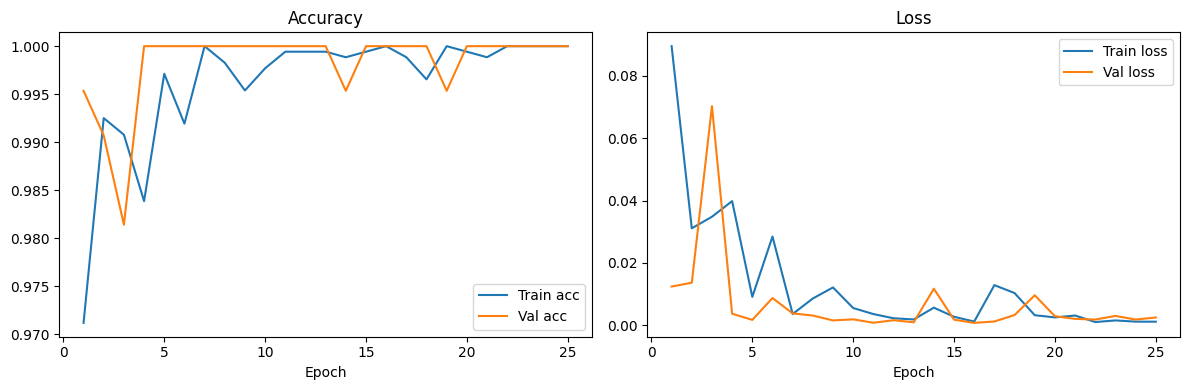

In [10]:
epochs_range = [h["epoch"] for h in history]
train_accs = [h["train_acc"] for h in history]
val_accs = [h["val_acc"] for h in history]
train_losses = [h["train_loss"] for h in history]
val_losses = [h["val_loss"] for h in history]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_range, train_accs, label="Train acc")
axes[0].plot(epochs_range, val_accs, label="Val acc")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs_range, train_losses, label="Train loss")
axes[1].plot(epochs_range, val_losses, label="Val loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/training_curves.png", dpi=150)
plt.show()

### Proof #4 — test-set confusion matrix and classification report
This is the number that actually matters — performance on held-out test images the model never saw during training.

=== TEST SET CLASSIFICATION REPORT ===
                       precision    recall  f1-score   support

Potato___Early_blight     1.0000    1.0000    1.0000       100
 Potato___Late_blight     1.0000    1.0000    1.0000       100
     Potato___healthy     1.0000    1.0000    1.0000        16

             accuracy                         1.0000       216
            macro avg     1.0000    1.0000    1.0000       216
         weighted avg     1.0000    1.0000    1.0000       216



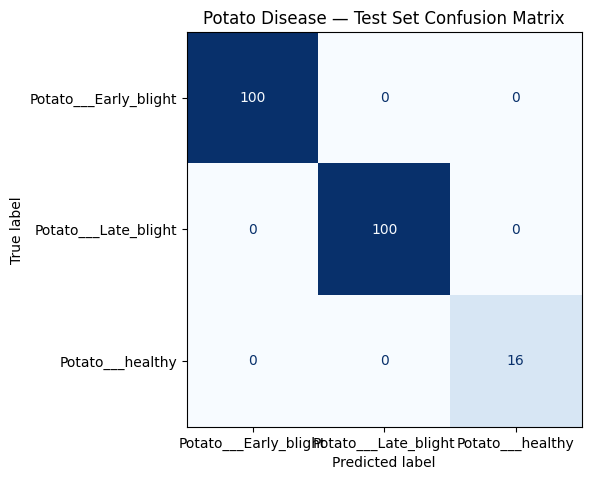

In [11]:
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))
model.eval()

all_preds, all_true = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_true.extend(labels.numpy())

print("=== TEST SET CLASSIFICATION REPORT ===")
print(classification_report(all_true, all_preds, target_names=CLASS_NAMES, digits=4))

cm = confusion_matrix(all_true, all_preds)
fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Potato Disease — Test Set Confusion Matrix")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/confusion_matrix.png", dpi=150)
plt.show()

### Proof #5 — qualitative sample predictions
A quick visual gut-check: real images with true label vs. predicted label and confidence, colored green (correct) or red (wrong).

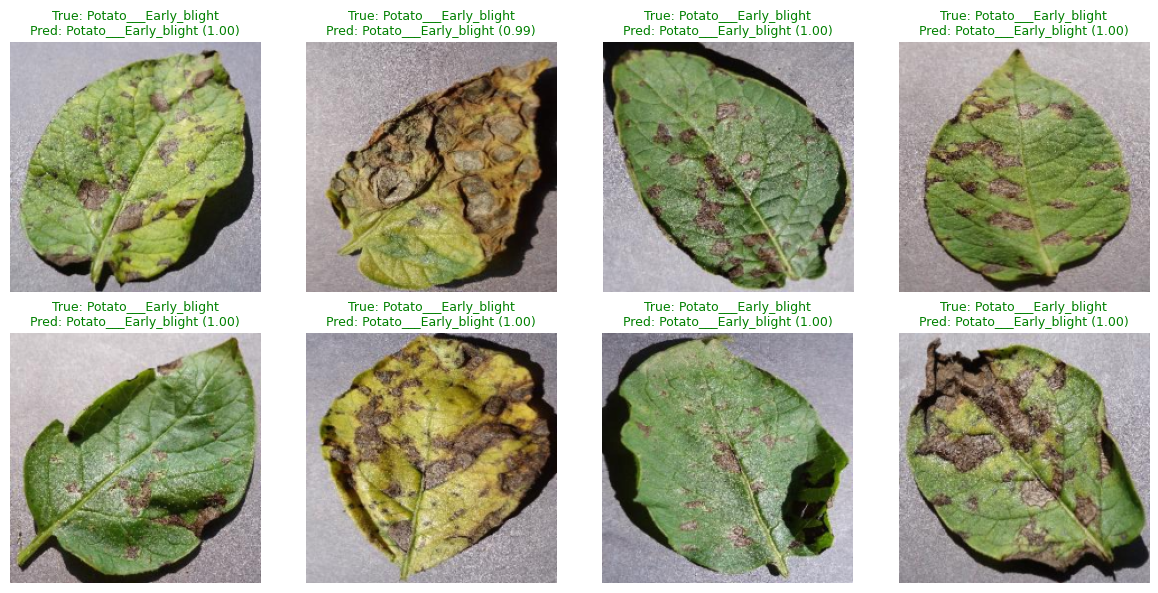

In [12]:
model.eval()
images, labels = next(iter(test_loader))
images_gpu = images.to(DEVICE)
with torch.no_grad():
    outputs = model(images_gpu)
    preds = outputs.argmax(1).cpu()
    probs = torch.softmax(outputs, dim=1).cpu()

n_show = min(8, len(images))
fig, axes = plt.subplots(2, max(1, n_show // 2), figsize=(3 * max(1, n_show // 2), 6))
axes = axes.flatten() if n_show > 1 else [axes]

unnorm_mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
unnorm_std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

for i in range(n_show):
    img = images[i] * unnorm_std + unnorm_mean
    img = img.permute(1, 2, 0).clamp(0, 1).numpy()
    axes[i].imshow(img)
    true_name = CLASS_NAMES[labels[i]]
    pred_name = CLASS_NAMES[preds[i]]
    conf = probs[i][preds[i]].item()
    color = "green" if preds[i] == labels[i] else "red"
    axes[i].set_title(f"True: {true_name}\nPred: {pred_name} ({conf:.2f})", color=color, fontsize=9)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

### Final step — export to ONNX for efficient deployment
Saves the deployable model and the class-name mapping (needed at inference time to turn output indices back into disease names).

In [14]:
!pip install -q onnx onnxscript onnxruntime
model.eval()
dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)

torch.onnx.export(
    model,
    dummy_input,
    ONNX_EXPORT_PATH,
    input_names=["image"],
    output_names=["disease_logits"],
    dynamic_axes={"image": {0: "batch_size"}, "disease_logits": {0: "batch_size"}},
    opset_version=13,
)
print(f"Exported ONNX model -> {ONNX_EXPORT_PATH}")

try:
    import onnxruntime as ort
    sess = ort.InferenceSession(ONNX_EXPORT_PATH, providers=["CPUExecutionProvider"])
    onnx_out = sess.run(None, {"image": dummy_input.cpu().numpy()})[0]
    with torch.no_grad():
        torch_out = model(dummy_input).cpu().numpy()
    max_diff = abs(onnx_out - torch_out).max()
    print(f"Max diff between PyTorch and ONNX output: {max_diff:.6f}")
except ImportError:
    print("Run 'pip install onnxruntime' to verify the ONNX export matches the PyTorch output.")

with open(f"{OUTPUT_DIR}/class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f)
print(f"Saved class name mapping -> {OUTPUT_DIR}/class_names.json")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 55.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 9.7 MB/s eta 0:00:00


/tmp/ipykernel_1362/3905441856.py:5: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W1020 18:55:13.235000 1362 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 13 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features


[torch.onnx] Obtain model graph for `PotatoDiseaseModel([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `PotatoDiseaseModel([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅


Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
        func=_partial_convert_version, model=model
    )
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
  File "/usr/local/lib/python3.13/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _partial_convert_version
    return onnx.version_converter.convert_version(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        proto, target_version=self.target_version
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/onnx/version_converter.py", line 39, in convert_version
    converted_model_str = C.convert_version(model_str, target_version)
RuntimeError: /project/onnx/version_converter/adapters/axes_input_to_attribute.h:55: 

[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Exported ONNX model -> /content/drive/MyDrive/potato_model/potato_disease_model.onnx
Max diff between PyTorch and ONNX output: 0.000001
Saved class name mapping -> /content/drive/MyDrive/potato_model/class_names.json
